# 02 — Qualité des données et horizon du dataset d'entraînement

Objectif : savoir **sur quelle période** et **avec quelles sources** construire un dataset d'entraînement complet et
unifié pour prédire le couple **(débit horaire, taux d'occupation)** des 3 arcs du brief.

Prérequis : `python -m src.data.update --history 2010 2025` puis `python -m src.data.build_traffic`.

1. Horizon disponible par source
2. Trafic : complétude et trous
3. Trafic : valeurs aberrantes et capteurs figés
4. Ruptures de régime (30 km/h, Covid, JO…)
5. Le couple cible (débit, occupation)
6. Champs-Elysées : capteur muet et proxys
7. Météo : observé vs prévision
8. Calendrier, événements, chantiers
9. Synthèse et recommandations

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.config import ARCS, TZ, TARGETS, DATA_DIR, TRAFFIC_PATH

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90

ARC_IDS = {"Champs-Elysées": "4264", "Convention": "5671", "Saint-Pères": "191"}
COLORS = dict(zip(ARCS, sns.color_palette("tab10", 3)))

# Dates de rupture potentielles, à confronter aux données
REPERES = {
    "Confinement 1": ("2020-03-17", "2020-05-10"),
    "Confinement 2": ("2020-10-30", "2020-12-14"),
    "Confinement 3": ("2021-04-03", "2021-05-02"),
    "JO 2024": ("2024-07-18", "2024-09-08"),
}
VILLE_30 = pd.Timestamp("2021-08-30", tz="UTC")   # 30 km/h généralisé à Paris (hors quelques grands axes)

traffic = pd.read_parquet(TRAFFIC_PATH)
traffic["local"] = traffic["datetime"].dt.tz_convert(TZ)
print(traffic.groupby("arc")["datetime"].agg(["min", "max", "size"]))

                                     min                       max    size
arc                                                                       
Champs-Elysées 2010-01-01 00:00:00+00:00 2026-11-02 23:00:00+00:00  147600
Convention     2010-01-01 00:00:00+00:00 2026-11-02 23:00:00+00:00  147600
Saint-Pères    2010-01-01 00:00:00+00:00 2026-11-02 23:00:00+00:00  147600


In [2]:
def load_raw(columns=None):
    files = sorted(glob.glob(str(DATA_DIR / "trafic/historique/*.parquet"))) + [str(DATA_DIR / "trafic/recent.parquet")]
    df = pd.concat([pd.read_parquet(f, columns=columns) for f in files], ignore_index=True)
    return df.drop_duplicates(["arc_id", "datetime"], keep="last")

raw = load_raw(["arc_id", "nd_amont", "nd_aval", "libelle", "datetime", "debit_horaire", "taux_occupation", "etat_arc", "source"])
raw["valide"] = raw[TARGETS].notna().all(axis=1) & (raw["etat_arc"] != "Invalide")
print(f"{len(raw):,} lignes, {raw['arc_id'].nunique()} arcs, {raw['datetime'].min()} -> {raw['datetime'].max()}")

def shade(ax):
    for name, (a, b) in REPERES.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15)
    ax.axvline(VILLE_30.tz_localize(None), color="red", ls="--", lw=1)

7,451,251 lignes, 51 arcs, 2010-01-01 00:00:00+00:00 -> 2026-11-02 23:00:00+00:00


## 1. Horizon disponible par source

Pour chaque source : première et dernière date disponibles, et ce qu'elle couvre de la fenêtre à prédire (07 → 11/11/2026).
Pour le trafic, on prend la première et la dernière heure **valide** (débit et occupation présents, arc non invalide).

In [3]:
def span(path, col, **kw):
    df = pd.read_parquet(DATA_DIR / path)
    s = pd.to_datetime(df[col], **kw)
    return s.min(), s.max(), len(df)

rows = []
for arc, iu in ARC_IDS.items():
    v = traffic[(traffic["arc"] == arc) & traffic["is_valid"]]["datetime"]
    rows.append(("trafic", f"{arc} (arc {iu})", v.min(), v.max(), len(v)))
for name in ["historique", "prevision_historique", "prevision"]:
    rows.append(("meteo", name, *span(f"meteo/{name}.parquet", "datetime")))
rows.append(("calendrier", "jours_feries", *span("calendrier/jours_feries.parquet", "date")))
rows.append(("calendrier", "vacances_scolaires", *span("calendrier/vacances_scolaires.parquet", "debut")))
rows.append(("evenements", "evenements (manuels)", *span("evenements/evenements.parquet", "debut")))
rows.append(("evenements", "que_faire_a_paris", *span("evenements/que_faire_a_paris.parquet", "date_start")))
for name in ["chantiers_perturbants", "chantiers_a_paris", "chantiers_2024"]:
    rows.append(("chantiers", name, *span(f"chantiers/{name}.parquet", "date_debut")))

horizons = pd.DataFrame(rows, columns=["source", "jeu", "debut", "fin", "lignes"])
horizons["debut"] = pd.to_datetime(horizons["debut"], utc=True).dt.tz_localize(None)
horizons["fin"] = pd.to_datetime(horizons["fin"], utc=True).dt.tz_localize(None)
horizons["couvre_07-11/11"] = horizons["fin"] >= pd.Timestamp("2026-11-11 23:00")
horizons

,source,jeu,debut,fin,lignes,couvre_07-11/11
0,trafic,Champs-Elysées (arc 4264),2010-01-01,2025-11-19 10:00:00,129585,False
1,trafic,Convention (arc 5671),2010-01-01,2026-11-02 23:00:00,129297,False
2,trafic,Saint-Pères (arc 191),2010-01-01,2026-11-02 23:00:00,133705,False
3,meteo,historique,2010-01-01,2026-11-02 23:00:00,147600,False
4,meteo,prevision_historique,2022-01-01,2026-11-02 23:00:00,42408,False
5,meteo,prevision,2026-10-27,2026-11-18 23:00:00,552,True
6,calendrier,jours_feries,2006-01-01,2031-12-25 00:00:00,285,True
7,calendrier,vacances_scolaires,2017-10-21,2028-07-04 00:00:00,65,True
8,evenements,evenements (manuels),2010-05-08,2027-12-31 00:00:00,72,True
9,evenements,que_faire_a_paris,2019-06-01,2029-06-08 19:00:00,3154,True


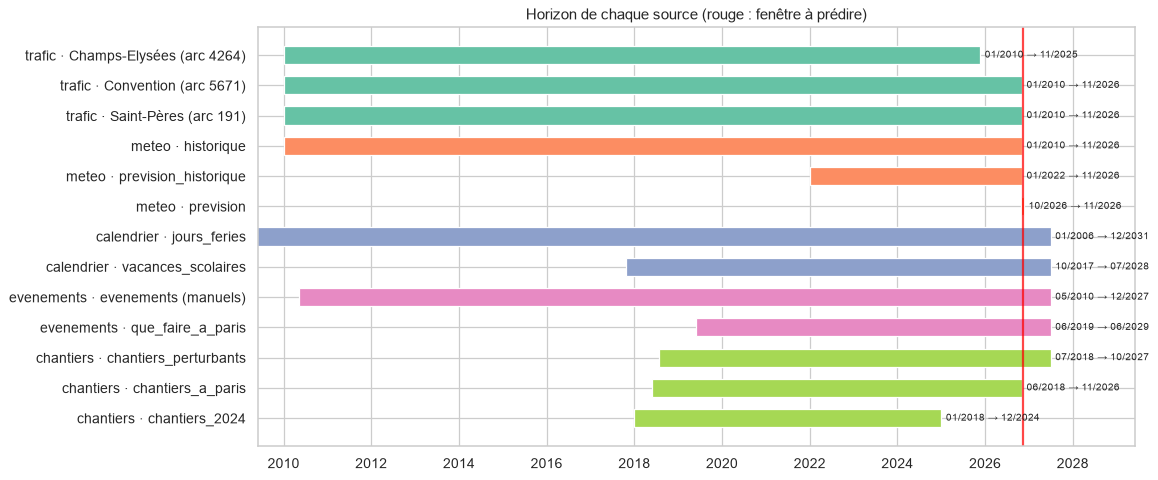

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.5))
pal = dict(zip(horizons["source"].unique(), sns.color_palette("Set2", 5)))
for i, r in horizons.iloc[::-1].reset_index(drop=True).iterrows():
    fin = min(r["fin"], pd.Timestamp("2027-06-30"))
    ax.barh(i, (fin - r["debut"]).days, left=r["debut"], color=pal[r["source"]], height=0.6)
    ax.text(fin + pd.Timedelta(days=40), i, f'{r["debut"]:%m/%Y} → {r["fin"]:%m/%Y}', va="center", fontsize=8)
ax.set_yticks(range(len(horizons)), horizons["source"].iloc[::-1] + " · " + horizons["jeu"].iloc[::-1])
ax.axvspan(pd.Timestamp("2026-11-07"), pd.Timestamp("2026-11-12"), color="red", alpha=0.6)
ax.set_xlim(pd.Timestamp("2009-06-01"), pd.Timestamp("2029-06-01"))
ax.set_title("Horizon de chaque source (rouge : fenêtre à prédire)")
plt.tight_layout(); plt.show()

**Lecture**
- Le trafic, la météo observée et les jours fériés remontent à **2010** : c'est le socle commun.
- Les **vacances scolaires** ne commencent qu'en **octobre 2017** dans l'open data : toute feature « vacances »
  borne le dataset à 2017, ou impose de saisir 2010-2017 à la main (dates publiques, faisable).
- Les **prévisions archivées** commencent en **2022** : seule période où l'on peut backtester avec la météo
  telle qu'elle était connue au moment de prédire.
- **Chantiers** et **Que faire à Paris** n'ont pas d'historique exploitable (pas de dates passées fiables avant 2024) :
  inutilisables comme features d'entraînement sur plusieurs années, au mieux comme indicateur ponctuel pour la fenêtre.

## 2. Trafic : complétude et trous

Part d'heures valides par mois, pour les 3 arcs du brief.

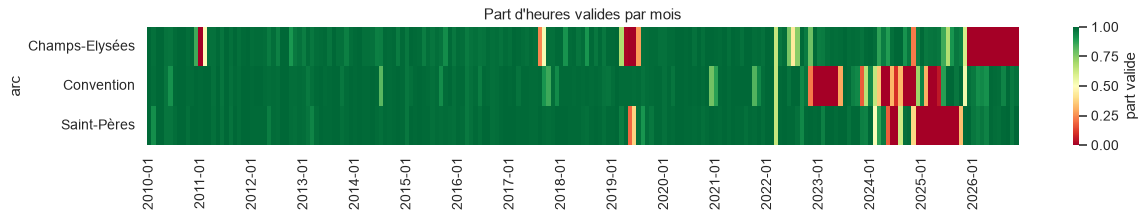

arc,Champs-Elysées,Convention,Saint-Pères
datetime,,,
2010,98%,99%,99%
2011,87%,99%,99%
2012,97%,99%,99%
2013,98%,99%,99%
2014,98%,98%,99%
2015,98%,98%,99%
2016,98%,99%,99%
2017,89%,97%,99%
2018,97%,99%,99%


In [5]:
traffic["mois"] = traffic["datetime"].dt.tz_localize(None).dt.to_period("M")
monthly_valid = traffic.groupby(["arc", "mois"])["is_valid"].mean().unstack("mois")

fig, ax = plt.subplots(figsize=(14, 2.6))
sns.heatmap(monthly_valid, cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "part valide"}, ax=ax,
            xticklabels=12)
ax.set_xlabel(""); ax.set_title("Part d'heures valides par mois")
plt.tight_layout(); plt.show()

yearly = traffic.groupby(["arc", traffic["datetime"].dt.year])["is_valid"].mean().unstack("arc").round(2)
yearly.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1).format("{:.0%}")

In [6]:
def gaps(s: pd.Series) -> pd.Series:
    # Longueur (en heures) de chaque séquence d'heures non valides consécutives
    run = (s != s.shift()).cumsum()
    return s[~s].groupby(run[~s]).size()

g = {arc: gaps(d.set_index("datetime")["is_valid"]) for arc, d in traffic.groupby("arc")}
gap_stats = pd.DataFrame({arc: {
    "nb_trous": len(x), "≤ 3 h": (x <= 3).sum(), "4 h – 1 j": ((x > 3) & (x <= 24)).sum(),
    "1 j – 1 sem.": ((x > 24) & (x <= 168)).sum(), "> 1 sem.": (x > 168).sum(),
    "heures dans trous > 1 sem.": x[x > 168].sum(), "plus long (j)": round(x.max() / 24, 1)} for arc, x in g.items()}).T
gap_stats

,nb_trous,≤ 3 h,4 h – 1 j,1 j – 1 sem.,> 1 sem.,heures dans trous > 1 sem.,plus long (j)
Champs-Elysées,1188.0,1005.0,161.0,15.0,7.0,14190.0,348.5
Convention,764.0,667.0,62.0,23.0,12.0,15481.0,226.7
Saint-Pères,744.0,679.0,53.0,7.0,5.0,12242.0,343.0


In [7]:
# Les longs trous : où sont-ils ?
long_gaps = []
for arc, d in traffic.groupby("arc"):
    s = d.set_index("datetime")["is_valid"]
    run = (s != s.shift()).cumsum()
    for _, grp in s[~s].groupby(run[~s]):
        if len(grp) > 24 * 14:
            long_gaps.append((arc, grp.index.min().date(), grp.index.max().date(), round(len(grp) / 24)))
pd.DataFrame(long_gaps, columns=["arc", "debut", "fin", "jours"])

,arc,debut,fin,jours
0,Champs-Elysées,2010-12-27,2011-02-15,50
1,Champs-Elysées,2017-08-08,2017-09-14,37
2,Champs-Elysées,2019-04-01,2019-07-23,113
3,Champs-Elysées,2022-06-24,2022-07-18,24
4,Champs-Elysées,2025-11-19,2026-11-02,349
5,Convention,2022-11-07,2023-06-22,227
6,Convention,2023-11-06,2023-12-11,35
7,Convention,2024-03-13,2024-06-21,100
8,Convention,2024-07-05,2024-08-12,38
9,Convention,2024-08-22,2024-12-06,106


In [8]:
# Débit sans occupation ou l'inverse, et codes d'état de l'arc par année
partial = traffic.groupby("arc").apply(lambda d: pd.Series({
    "débit seul": (d["debit_horaire"].notna() & d["taux_occupation"].isna()).mean(),
    "occupation seule": (d["debit_horaire"].isna() & d["taux_occupation"].notna()).mean(),
    "les deux manquants": d[TARGETS].isna().all(axis=1).mean()}), include_groups=False)
display(partial.style.format("{:.2%}"))
pd.crosstab([traffic["arc"], traffic["datetime"].dt.year], traffic["etat_arc"].fillna("absent")).unstack("arc").fillna(0).astype(int)

,débit seul,occupation seule,les deux manquants
arc,,,
Champs-Elysées,0.73%,0.25%,11.22%
Convention,0.07%,4.56%,7.78%
Saint-Pères,0.00%,0.02%,9.39%


etat_arc          Barré                              Invalide                                Ouvert                                absent                                code_1                       
arc      Champs-Elysées Convention Saint-Pères Champs-Elysées Convention Saint-Pères Champs-Elysées Convention Saint-Pères Champs-Elysées Convention Saint-Pères Champs-Elysées Convention Saint-Pères
datetime                                                                                                                                                                                              
2010                  0          0           0              0          0           0              7          7           7              2          2           2           8751       8751        8751
2011                  0          0           0              0          0           0             28         28          28              2          2           2           8730       8730        8730
2012                  0          0           0              0          0           0           5547       5547        5547              2          2           2           3235       3235        3235
2013                  0          0           0              0          0           0           8757       8757        8757              3          3           3              0          0           0
2014                 42          0           5              0          0           0           8716       8758        8753              2          2           2              0          0           0
2015                 77          0           8              0          0           0           8680       8757        8749              3          3           3              0          0           0
2016                142          0           9              0          0           0           8639       8781        8772              3          3           3              0          0           0
2017                165          7           8              0          0           0           8592       8750        8749              3          3           3              0          0           0
2018                245          0        1782              0          0           0           8510       8755        6973              5          5           5              0          0           0
2019                210          1           0              0          0           0           8547       8756        8757              3          3           3              0          0           0
2020                 94          2           4              0          0           0           8688       8780        8778              2          2           2              0          0           0
2021                 71          0           2              0          0           0           8684       8755        8753              5          5           5              0          0           0
2022                 81          0           0              0          0           0           8552       8633        8633            127        127         127              0          0           0
2023                122          0           8              0          0           0           8635       8757        8749              3          3           3              0          0           0
2024                189          0           0              0          0           0           8083       8272        8272            512        512         512              0          0           0
2025                122          0           0           1023        350         498           7614       8409        8261              1          1           1              0          0           0
2026                127          0           0           7088        163          57              0       7052        7158            129        129         129              0          0           0

**Lecture**
- 2010-2021 : complétude excellente (≥ 97 %) sur les 3 arcs, à quelques années près (Champs-Elysées 2019).
- **Dégradation récente** : Convention perd 58 % des heures en 2023 et 72 % en 2024, Saint-Pères 46 % en 2024
  et 81 % en 2025, Champs-Elysées est muet depuis le 19/11/2025. Ces trous sont de **longs blocs** (semaines/mois),
  pas des heures isolées : l'interpolation n'a pas de sens, il faut les exclure de l'entraînement.
- Les manques partiels (débit sans occupation) sont marginaux, sauf Convention (~4,5 % d'heures avec occupation
  sans débit) : on garde une ligne seulement si **les deux** cibles sont présentes.
- `code_1` (2010-2012) recouvre des heures avec débit et occupation normaux : c'est l'ancien codage d'« Ouvert ».

## 3. Trafic : valeurs aberrantes et capteurs figés

In [9]:
v = traffic[traffic["is_valid"]]
desc = v.groupby("arc")[TARGETS].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1)
display(desc)

def stuck(d, col, min_len=6):
    # Heures appartenant à une séquence d'au moins `min_len` valeurs identiques non nulles
    x = d[col]
    run = (x != x.shift()).cumsum()
    size = x.groupby(run).transform("size")
    return ((size >= min_len) & x.notna() & (x > 0)).mean()

pd.DataFrame({arc: {"débit figé ≥ 6 h": stuck(d, "debit_horaire"), "occupation figée ≥ 6 h": stuck(d, "taux_occupation"),
                    "débit = 0": (d["debit_horaire"] == 0).mean(), "occupation > 50 %": (d["taux_occupation"] > 50).mean()}
              for arc, d in traffic.groupby("arc")}).T.style.format("{:.3%}")

arc                    Champs-Elysées  Convention  Saint-Pères
debit_horaire   count        129585.0    129297.0     133705.0
                mean           1157.3       450.5        486.3
                std             637.9       282.4        281.9
                min               0.0         8.0          0.0
                1%               51.0        38.0         30.0
                50%            1086.0       440.0        505.0
                99%            2503.0      1106.0       1025.0
                max            6530.0      1386.0      33272.0
taux_occupation count        129585.0    129297.0     133705.0
                mean             12.0         5.9          7.0
                std               9.9         7.5          5.7
                min               0.0         0.0          0.0
                1%                0.6         0.2          0.4
                50%               9.8         3.6          6.0
                99%              49.8        40.0         29.0
                max              99.0        65.5        100.0

,débit figé ≥ 6 h,occupation figée ≥ 6 h,débit = 0,occupation > 50 %
Champs-Elysées,0.000%,0.021%,0.024%,0.866%
Convention,0.000%,0.329%,0.000%,0.240%
Saint-Pères,0.000%,0.049%,0.001%,0.007%


In [10]:
# Pics isolés : débit > 2 x le quantile 99,9 % de l'arc (une voie urbaine plafonne vers 1 800-2 000 véh/h/voie)
q999 = v.groupby("arc")["debit_horaire"].quantile(0.999)
spikes = v[v["debit_horaire"] > 2 * v["arc"].map(q999)]
spikes[["arc", "local", "debit_horaire", "taux_occupation", "etat_arc"]]

,arc,local,debit_horaire,taux_occupation,etat_arc
67800,Champs-Elysées,2017-09-26 02:00:00+02:00,5857.0,3.19722,Ouvert
67821,Champs-Elysées,2017-09-26 23:00:00+02:00,6460.0,6.61889,Ouvert
67822,Champs-Elysées,2017-09-27 00:00:00+02:00,6530.0,5.86722,Ouvert
376108,Saint-Pères,2019-03-26 05:00:00+01:00,33272.0,100.00000,Ouvert


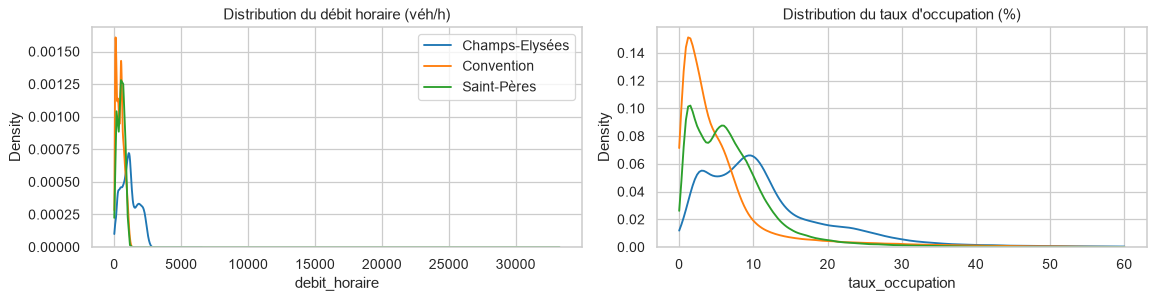

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for arc, d in v.groupby("arc"):
    sns.kdeplot(d["debit_horaire"], ax=axes[0], label=arc, color=COLORS[arc], cut=0)
    sns.kdeplot(d["taux_occupation"], ax=axes[1], label=arc, color=COLORS[arc], cut=0, clip=(0, 60))
axes[0].set_title("Distribution du débit horaire (véh/h)"); axes[1].set_title("Distribution du taux d'occupation (%)")
axes[0].legend(); plt.tight_layout(); plt.show()

**Lecture** : pas de débit négatif ni d'occupation > 100 %. Quelques **pics isolés absurdes** (ex. Saint-Pères à
33 272 véh/h) : à invalider avec un seuil par arc. Les capteurs figés et les débits nuls sont rares (ordre du pour
mille) : un filtre simple suffit (séquences figées ≥ 6 h → invalides).

## 4. Ruptures de régime

Médiane mensuelle, jours ouvrés 8 h-20 h (heure de Paris), pour neutraliser les effets calendaires.
Zones grises : confinements et JO 2024. Ligne rouge : 30 km/h généralisé à Paris (30/08/2021).

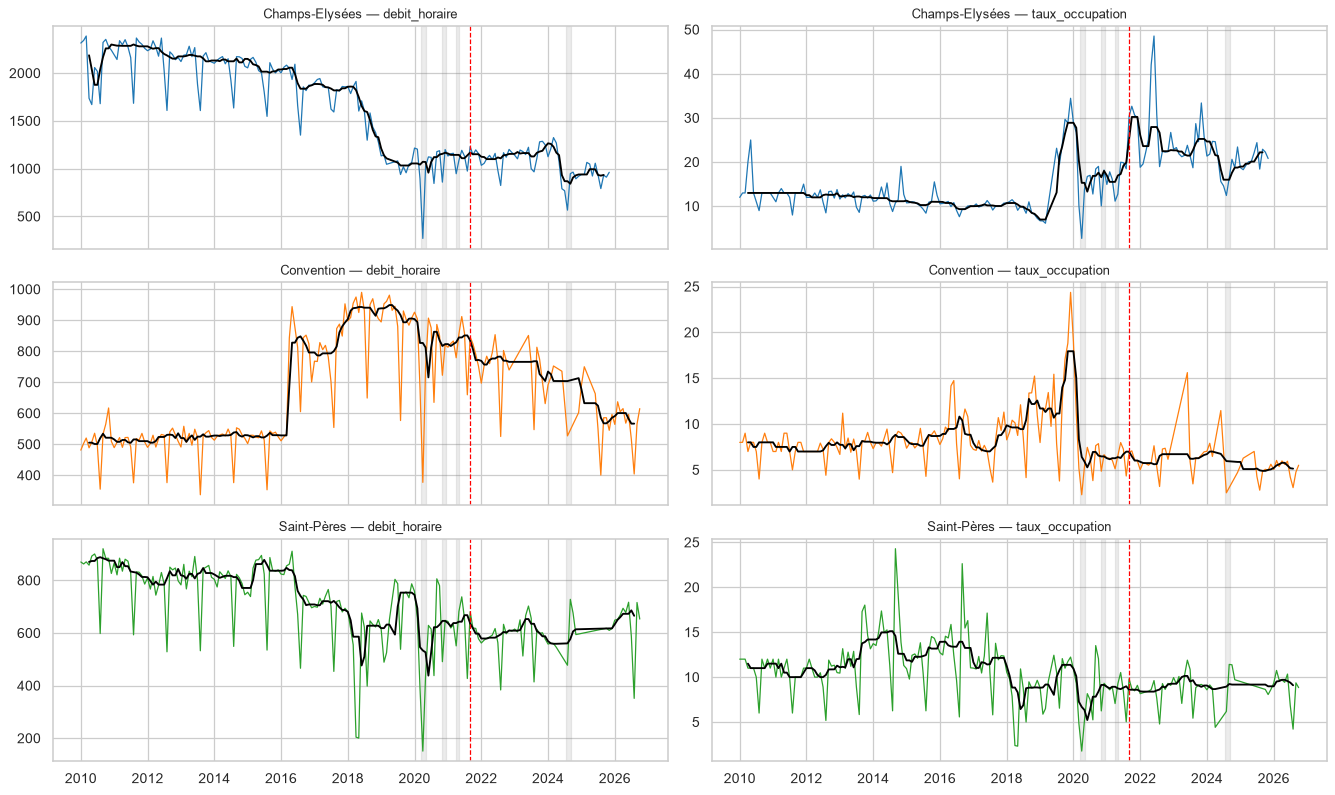

In [12]:
jo = traffic["is_valid"] & (traffic["local"].dt.day_of_week < 5) & traffic["local"].dt.hour.between(8, 19)
m = traffic[jo].groupby(["arc", traffic.loc[jo, "datetime"].dt.tz_localize(None).dt.to_period("M")])[TARGETS].median()
m = m[traffic[jo].groupby(["arc", traffic.loc[jo, "datetime"].dt.tz_localize(None).dt.to_period("M")]).size() >= 50]

fig, axes = plt.subplots(3, 2, figsize=(15, 9), sharex=True)
for i, arc in enumerate(ARCS):
    d = m.loc[arc]
    for j, col in enumerate(TARGETS):
        ax = axes[i, j]
        ax.plot(d.index.to_timestamp(), d[col], color=COLORS[arc], lw=1)
        ax.plot(d.index.to_timestamp(), d[col].rolling(6, center=True).median(), color="black", lw=1.5)
        shade(ax); ax.set_title(f"{arc} — {col}", fontsize=10)
plt.tight_layout(); plt.show()

In [13]:
# Comparaison avant / après 30 km/h, à saison égale (sept.-déc. 2019 vs sept.-déc. 2021, hors confinements)
def period_stats(a, b):
    s = traffic[jo & (traffic["datetime"] >= pd.Timestamp(a, tz="UTC")) & (traffic["datetime"] < pd.Timestamp(b, tz="UTC"))]
    return s.groupby("arc")[TARGETS].median()

compare = pd.concat({"sept-déc 2019": period_stats("2019-09-01", "2020-01-01"),
                     "sept-déc 2021": period_stats("2021-09-01", "2022-01-01"),
                     "sept-déc 2022": period_stats("2022-09-01", "2023-01-01"),
                     "sept-déc 2025": period_stats("2025-09-01", "2026-01-01")}, axis=1).round(1)
compare

sept-déc 2019                 sept-déc 2021                 sept-déc 2022                 sept-déc 2025                
               debit_horaire taux_occupation debit_horaire taux_occupation debit_horaire taux_occupation debit_horaire taux_occupation
arc                                                                                                                                   
Champs-Elysées        1020.0            28.6        1185.0            30.7        1165.0            23.2         926.5            22.0
Convention             905.0            17.5         809.0             6.5         783.0             7.2         581.0             5.1
Saint-Pères            755.0            11.6         627.0             9.0         610.0             9.1         613.0             8.4

In [14]:
# Détection automatique : plus fort changement de niveau de la médiane mensuelle (fenêtres de 12 mois avant/après)
def biggest_breaks(series, w=12, top=3):
    s = series.dropna()
    before = s.rolling(w).median()
    after = s[::-1].rolling(w).median()[::-1].shift(-1)
    ratio = (after / before).dropna()
    out = []
    for p in (ratio - 1).abs().sort_values(ascending=False).index:
        if all(abs((p - q).n) > w for q in out):
            out.append(p)
        if len(out) == top:
            break
    return [(str(p), round(ratio[p], 2)) for p in sorted(out)]

pd.DataFrame({(arc, col): biggest_breaks(m.loc[arc, col]) for arc in ARCS for col in TARGETS}).T

0                1                2
Champs-Elysées debit_horaire     (2018-09, 0.6)  (2020-07, 1.11)  (2024-05, 0.76)
               taux_occupation  (2019-03, 2.78)   (2020-04, 0.7)  (2021-07, 1.78)
Convention     debit_horaire    (2016-03, 1.58)  (2017-11, 1.19)  (2024-03, 0.78)
               taux_occupation  (2017-12, 1.38)  (2019-01, 1.26)  (2020-03, 0.48)
Saint-Pères    debit_horaire     (2019-03, 1.2)  (2020-04, 0.84)  (2024-08, 1.16)
               taux_occupation  (2013-09, 1.32)  (2018-02, 0.72)  (2020-01, 0.73)

**Lecture**
- **Le 30 km/h (30/08/2021, ligne rouge) ne laisse aucune trace visible** sur les 3 arcs : ni sur le débit, ni sur
  l'occupation. Il n'impose donc pas de coupure dans le dataset (on garde quand même un indicateur `post_30kmh`).
- Les vraies ruptures sont ailleurs, et propres à chaque arc :
  - **Champs-Elysées, fin 2018 → mi-2019** : le débit de journée passe de ~1 850 à ~1 050 véh/h et l'occupation
    double (~10 % → ~20-25 %). C'est une **perte de capacité** (voir le diagramme fondamental en partie 5), typique
    d'une suppression de voie ou d'un réaménagement, coïncidant avec le trou de capteur d'avril-juillet 2019.
    Nouvelle marche vers le bas après les JO 2024 (~1 150 → ~950).
  - **Convention, mars 2016** : saut de débit (~520 → ~850 véh/h), puis **mars 2020** : l'occupation est divisée par
    deux à débit quasi égal (~12-17 % → ~6 %). Changement de la relation débit/occupation = probable **recalibrage
    du capteur** ou réaménagement. Lente baisse du débit depuis 2023 (~770 → ~600).
  - **Saint-Pères** : le plus stable ; baisse progressive 2016-2018, creux en 2018 (arc barré), niveau stable depuis 2021.
- Le **Covid** (mars 2020 → mi-2021) est une anomalie nette sur les 3 arcs : à exclure ou marquer.

Conséquence : un régime **comparable à aujourd'hui pour les 3 arcs à la fois** n'existe qu'à partir de **mi-2020**
(après la rupture de Convention), et proprement à partir de **mi-2021** (après le Covid).

## 5. Le couple cible (débit, occupation)

Débit et occupation sont liés par le **diagramme fondamental** du trafic : en régime fluide le débit croît avec
l'occupation, puis plafonne et décroît à saturation. Un changement de vitesse ou de capacité déplace cette courbe.

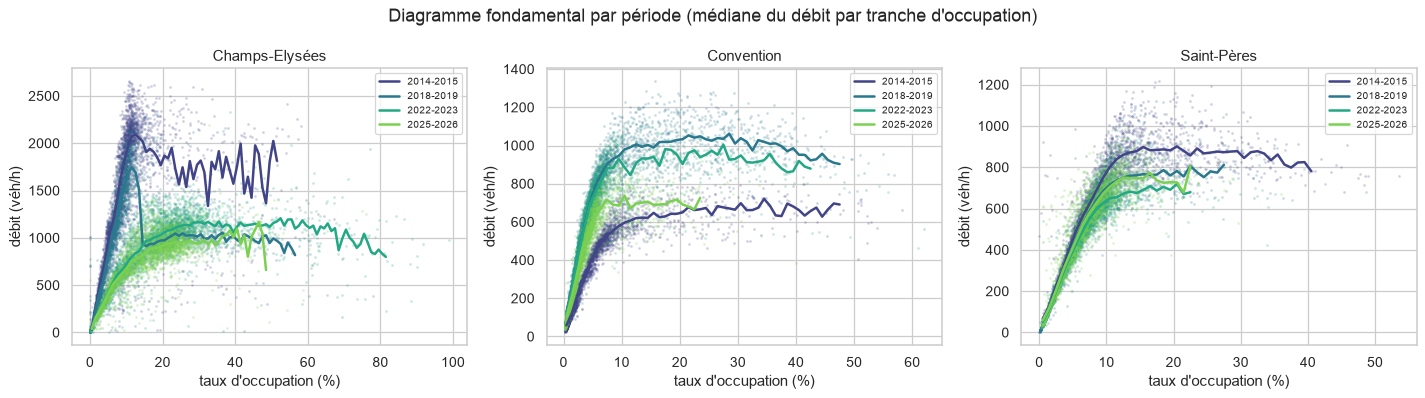

In [15]:
periods = {"2014-2015": ("2014-01-01", "2016-01-01"), "2018-2019": ("2018-01-01", "2020-01-01"),
           "2022-2023": ("2022-01-01", "2024-01-01"), "2025-2026": ("2025-01-01", "2026-12-31")}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, arc in zip(axes, ARCS):
    d = v[v["arc"] == arc]
    for (name, (a, b)), c in zip(periods.items(), sns.color_palette("viridis", 4)):
        s = d[(d["datetime"] >= pd.Timestamp(a, tz="UTC")) & (d["datetime"] < pd.Timestamp(b, tz="UTC"))]
        if len(s) < 500:
            continue
        bins = pd.cut(s["taux_occupation"], np.arange(0, s["taux_occupation"].quantile(0.995) + 1, 1))
        curve = s.groupby(bins, observed=True)["debit_horaire"].median()
        ax.scatter(s["taux_occupation"].sample(min(len(s), 3000), random_state=0),
                   s["debit_horaire"].sample(min(len(s), 3000), random_state=0), s=2, alpha=0.15, color=c)
        ax.plot([i.mid for i in curve.index], curve.values, color=c, lw=2, label=name)
    ax.set_title(arc); ax.set_xlabel("taux d'occupation (%)"); ax.set_ylabel("débit (véh/h)"); ax.legend(fontsize=8)
plt.suptitle("Diagramme fondamental par période (médiane du débit par tranche d'occupation)")
plt.tight_layout(); plt.show()

datetime,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
arc,,,,,,,,,,,,,,,,,
Champs-Elysées,0.78,0.84,0.84,0.81,0.66,0.76,0.86,0.87,0.90,0.57,0.94,0.84,0.76,0.74,0.82,0.80,NaN
Convention,0.95,0.97,0.98,0.98,0.98,0.98,0.89,0.97,0.96,0.95,0.98,0.98,0.97,0.96,0.91,0.97,0.96
Saint-Pères,0.96,0.96,0.96,0.96,0.94,0.97,0.95,0.96,0.98,0.97,0.99,0.97,0.97,0.97,0.90,0.93,0.94


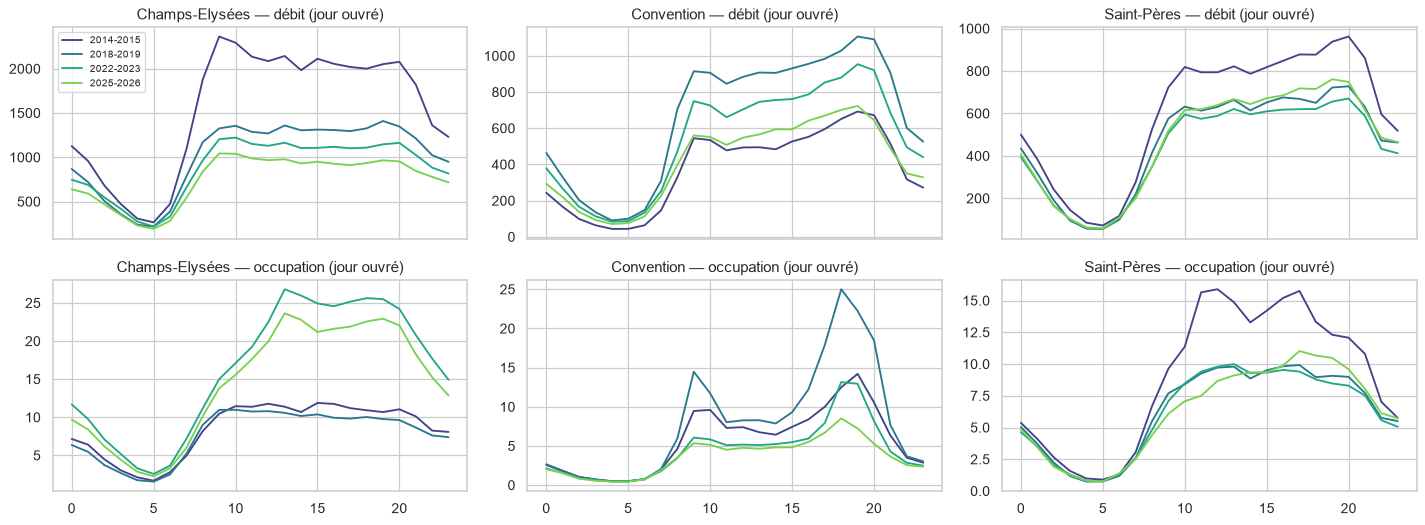

In [16]:
# Corrélation débit / occupation et profils horaires moyens (jour ouvré) par période
corr = v.groupby(["arc", v["datetime"].dt.year]).apply(
    lambda d: d["debit_horaire"].corr(d["taux_occupation"], method="spearman"), include_groups=False).unstack("arc").round(2)
display(corr.T)

fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharex=True)
wd = v[v["local"].dt.day_of_week < 5]
for j, arc in enumerate(ARCS):
    d = wd[wd["arc"] == arc]
    for (name, (a, b)), c in zip(periods.items(), sns.color_palette("viridis", 4)):
        s = d[(d["datetime"] >= pd.Timestamp(a, tz="UTC")) & (d["datetime"] < pd.Timestamp(b, tz="UTC"))]
        if len(s) < 500:
            continue
        prof = s.groupby(s["local"].dt.hour)[TARGETS].median()
        axes[0, j].plot(prof.index, prof["debit_horaire"], color=c, label=name)
        axes[1, j].plot(prof.index, prof["taux_occupation"], color=c, label=name)
    axes[0, j].set_title(f"{arc} — débit (jour ouvré)"); axes[1, j].set_title(f"{arc} — occupation (jour ouvré)")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Lecture**
- Débit et occupation sont fortement corrélés (Spearman 0,6-0,98, voir tableau) mais **pas redondants**, et leur
  relation (diagramme fondamental) **dépend de la période** : sur les Champs-Elysées la capacité a été divisée par
  ~2 entre 2014-2015 et 2022+ ; sur Convention la courbe 2022-2023 est très différente de 2014-2015, et 2025-2026
  plafonne plus bas que 2022-2023. Une relation apprise sur l'historique ancien serait fausse aujourd'hui.
- Les **profils horaires** gardent la même forme (pointes du matin et du soir), seul le niveau change : l'historique
  ancien peut servir à apprendre des effets **relatifs** (forme de la journée, jours fériés), pas des niveaux.
- Modélisation : deux modèles (un par cible) ou un multi-sorties, avec les **lags des deux cibles** en features ;
  vérifier ensuite que le couple prédit est cohérent avec le diagramme fondamental **récent**.

## 6. Champs-Elysées : capteur muet et proxys

L'arc 4264 (Washington → Berri) est muet depuis le 19/11/2025. On cherche les arcs de l'avenue qui émettent encore
et qui suivaient le mieux 4264 sur 2024-2025.

In [17]:
champs = raw[raw["nd_amont"].str.contains("Champs") | raw["nd_aval"].str.contains("Champs")].copy()
# Un même arc_id peut changer de nœuds au fil des ans : on identifie un arc par (arc_id, amont, aval)
champs["arc"] = champs["arc_id"] + " " + champs["nd_amont"] + " → " + champs["nd_aval"]
last6 = champs[champs["datetime"] >= pd.Timestamp("2026-05-01", tz="UTC")]
alive = last6.groupby("arc")["valide"].mean()
print("Part d'heures valides depuis mai 2026 :"); display(alive.sort_values(ascending=False).round(2).to_frame("valide"))
cand = alive[alive > 0.5].index.tolist()

ref = champs[(champs["arc_id"] == "4264") & champs["valide"]].set_index("datetime")[TARGETS]
win = (pd.Timestamp("2022-01-01", tz="UTC"), pd.Timestamp("2025-11-19", tz="UTC"))
rows = []
for lab in cand:
    d = champs[(champs["arc"] == lab) & champs["valide"]].set_index("datetime")[TARGETS].add_suffix("_p")
    j = ref.join(d, how="inner").loc[win[0]:win[1]]
    if len(j) < 1000:
        continue
    rows.append({"arc": lab, "heures communes": len(j),
                 "corr débit": j["debit_horaire"].corr(j["debit_horaire_p"]),
                 "corr occupation": j["taux_occupation"].corr(j["taux_occupation_p"]),
                 "ratio débit 4264/proxy": (j["debit_horaire"] / j["debit_horaire_p"]).median(),
                 "ratio occ. 4264/proxy": (j["taux_occupation"] / j["taux_occupation_p"]).median()})
proxies = pd.DataFrame(rows).sort_values("corr débit", ascending=False).round(2)
proxies

Part d'heures valides depuis mai 2026 :


,valide
arc,
4347 Av_Franklin_Roosevelt-Rocade_Sud → Rond_Point_Champs_Elysees,0.95
4281 Av_Champs_Elysees-Colisee → Rond_Point_Champs_Elysees,0.86
270 Av_Champs_Elysees-Clemenceau → Av_Champs_Elysees-Dutuit,0.79
6815 Av_Champs_Elysee_Souterrain → Pl_Concorde-Av_Champs_Elysees,0.79
226 Pl_Concorde-Av_Champs_Elysees → Concorde_Ouest,0.79
223 Av_Champs_Elysees-Dutuit → Av_Champs_Elysee_Souterrain,0.79
4274 Av_Champs_Elysees-Berri → Av_Champs_Elysees-La_Boetie,0.65
224 Pl_Concorde-Av_Champs_Elysees → Av_Champs_Elysees-Dutuit,0.64
4267 Av_Champs_Elysees-Balzac → Av_Champs_Elysees-Washington,0.42


,arc,heures communes,corr débit,corr occupation,ratio débit 4264/proxy,ratio occ. 4264/proxy
4,4274 Av_Champs_Elysees-Berri → Av_Champs_Elyse...,17576,0.95,0.46,1.05,1.99
5,4281 Av_Champs_Elysees-Colisee → Rond_Point_Ch...,28580,0.75,0.33,1.21,2.45
1,224 Pl_Concorde-Av_Champs_Elysees → Av_Champs_...,24364,0.71,0.41,3.19,8.09
0,223 Av_Champs_Elysees-Dutuit → Av_Champs_Elyse...,25453,0.62,0.34,5.99,5.40
2,226 Pl_Concorde-Av_Champs_Elysees → Concorde_O...,25453,0.62,0.34,5.99,5.40
7,6815 Av_Champs_Elysee_Souterrain → Pl_Concorde...,25453,0.62,0.34,3.00,5.40
3,270 Av_Champs_Elysees-Clemenceau → Av_Champs_E...,26202,0.61,0.46,3.04,2.70
6,4347 Av_Franklin_Roosevelt-Rocade_Sud → Rond_P...,24019,0.60,0.18,2.56,5.22


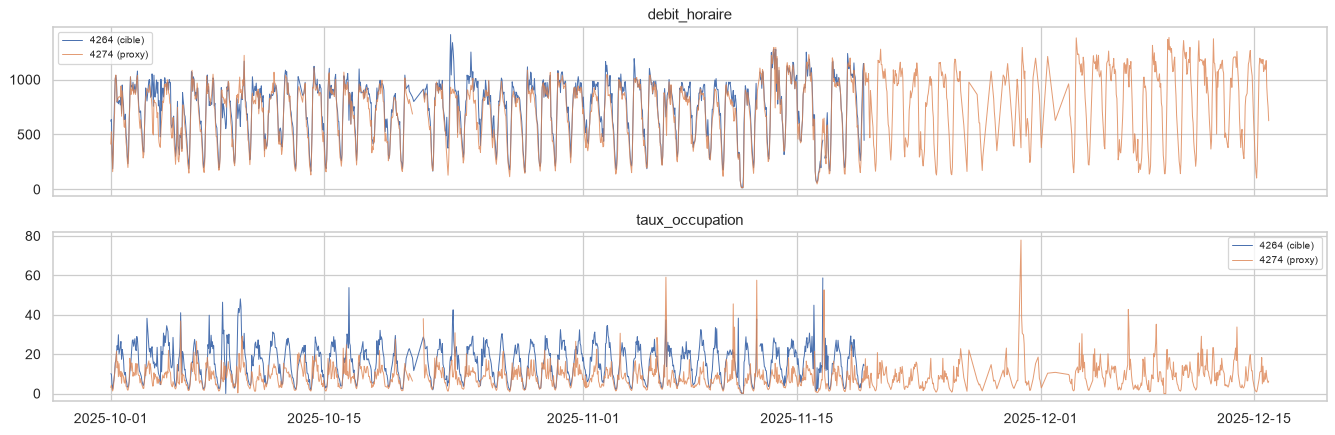

datetime,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
ratio débit,1.00,1.0,0.90,0.94,0.96,0.95,0.94,0.95,0.93,0.93,0.99,1.00,1.09,1.14,1.04,1.03,1.06,1.03,1.03,1.02,1.08,1.07
ratio occupation,5.76,0.0,1.96,1.64,1.42,1.42,1.56,1.26,1.24,1.37,1.51,1.74,2.23,2.15,1.81,1.73,2.23,2.10,1.96,2.24,1.89,1.86


In [18]:
best = proxies["arc"].iat[0]
p = champs[(champs["arc"] == best) & champs["valide"]].set_index("datetime")[TARGETS].add_suffix("_p")
w = ref.join(p, how="outer").loc["2025-10-01":"2025-12-15"]
fig, axes = plt.subplots(2, 1, figsize=(15, 5), sharex=True)
for ax, col in zip(axes, TARGETS):
    ax.plot(w.index, w[col], label="4264 (cible)", lw=0.8)
    ax.plot(w.index, w[f"{col}_p"], label=f"{best.split()[0]} (proxy)", lw=0.8, alpha=0.8)
    ax.set_title(col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Stabilité du ratio dans le temps : si le ratio dérive, un simple recalage ne suffit pas
j = ref.join(p, how="inner")
ratio = (j["debit_horaire"] / j["debit_horaire_p"]).groupby(j.index.tz_localize(None).to_period("Q")).median()
ratio_occ = (j["taux_occupation"] / j["taux_occupation_p"]).groupby(j.index.tz_localize(None).to_period("Q")).median()
pd.DataFrame({"ratio débit": ratio, "ratio occupation": ratio_occ}).loc["2019Q1":].round(2).T

**Lecture**
- **4274 (Berri → La Boétie)**, le tronçon juste en aval de 4264 dans le même sens, est de loin le meilleur proxy pour
  le **débit** : corrélation 0,95 et ratio 4264/4274 stable entre 0,9 et 1,1 depuis 2019. On peut reconstruire le débit
  de 4264 depuis le 19/11/2025 par `débit_4274 × ratio` (ratio par heure et type de jour, appris sur 2023-2025).
- Pour l'**occupation**, c'est moins bon : corrélation 0,46 et ratio ~2 (l'occupation dépend de la géométrie locale :
  feux, voie de bus…). Il faut un petit modèle de recalage (occupation 4264 ~ débit et occupation 4274 + heure),
  et accepter une erreur plus forte sur cette cible.
- 4274 est lui-même incomplet (0 % en août 2026, 31 % en septembre) mais **complet en octobre-novembre 2026**, ce qui
  couvre les lags dont on a besoin pour la fenêtre.
- Décision D1 à valider au tutorat du 05/11 : cible Champs-Elysées = 4264 jusqu'au 19/11/2025, puis 4274 recalé.

## 7. Météo : observé vs prévision

In [19]:
obs = pd.read_parquet(DATA_DIR / "meteo/historique.parquet").set_index("datetime")
fc = pd.read_parquet(DATA_DIR / "meteo/prevision_historique.parquet").set_index("datetime")
print("Valeurs manquantes (observé) :", int(obs.isna().sum().sum()), "| heures :", len(obs),
      "| grille continue :", obs.index.to_series().diff().dropna().eq(pd.Timedelta("1h")).all())

j = obs.join(fc.add_suffix("_fc"), how="inner")
err = pd.DataFrame({
    "MAE température (°C)": [(j["temperature_2m"] - j["temperature_2m_fc"]).abs().mean()],
    "MAE précipitations (mm/h)": [(j["precipitation"] - j["precipitation_fc"]).abs().mean()],
    "accord pluie oui/non": [((j["precipitation"] > 0.1) == (j["precipitation_fc"] > 0.1)).mean()],
    "MAE vent (km/h)": [(j["wind_speed_10m"] - j["wind_speed_10m_fc"]).abs().mean()],
}).round(2)
display(err)

Valeurs manquantes (observé) : 0 | heures : 147600 | grille continue : True


,MAE température (°C),MAE précipitations (mm/h),accord pluie oui/non,MAE vent (km/h)
0,0.83,0.09,0.93,2.52


⚠️ `prevision_historique` d'Open-Meteo est une **série reconstituée à partir des prévisions à courte échéance**
(premières heures de chaque run), pas la prévision à J+2…J+6 que nous aurons pour la fenêtre. L'écart réel au moment
du rendu sera plus grand que ci-dessus : la météo doit donc entrer dans le modèle sous une forme robuste (pluie
oui/non, tranches de température), et son apport doit être mesuré en backtest.

In [20]:
# Effet brut de la pluie sur le trafic (jours ouvrés 8-20 h, 2022+)
met = traffic[jo & (traffic["datetime"] >= pd.Timestamp("2022-01-01", tz="UTC"))].merge(
    obs[["precipitation", "temperature_2m"]], left_on="datetime", right_index=True)
met["pluie"] = pd.cut(met["precipitation"], [-0.1, 0.1, 1, 100], labels=["sec", "faible", "forte"])
met.groupby(["arc", "pluie"], observed=True)[TARGETS].median().unstack("pluie").round(1)

debit_horaire                 taux_occupation             
pluie                    sec  faible   forte             sec faible forte
arc                                                                      
Champs-Elysées        1058.0  1078.0  1078.5            21.6   20.8  20.7
Convention             650.0   645.0   687.0             5.3    5.8   6.9
Saint-Pères            600.0   608.0   615.0             8.6    9.2   9.6

## 8. Calendrier, événements, chantiers

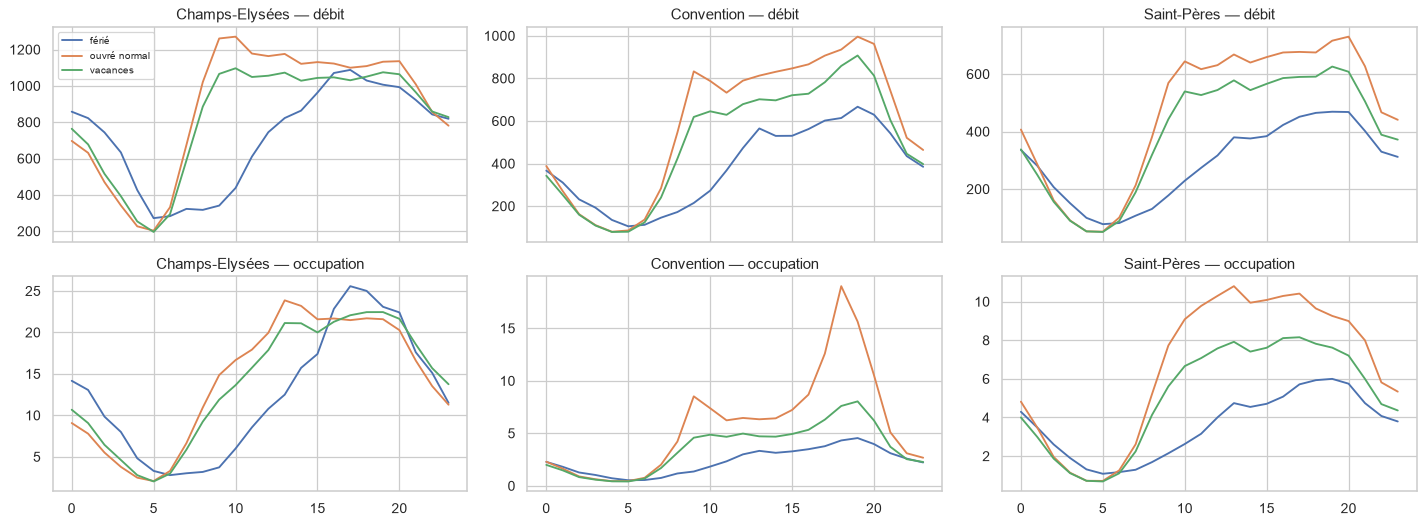

In [21]:
feries = pd.read_parquet(DATA_DIR / "calendrier/jours_feries.parquet")
vac = pd.read_parquet(DATA_DIR / "calendrier/vacances_scolaires.parquet")
days = traffic["local"].dt.date
traffic["ferie"] = days.isin(set(feries["date"]))
traffic["vacances"] = False
for r in vac.itertuples():
    traffic.loc[(days >= r.debut) & (days < r.fin), "vacances"] = True

recent = traffic[traffic["is_valid"] & (traffic["datetime"] >= pd.Timestamp("2018-01-01", tz="UTC"))
                 & (traffic["local"].dt.day_of_week < 5)].copy()
recent["type_jour"] = np.select([recent["ferie"], recent["vacances"]], ["férié", "vacances"], "ouvré normal")
fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharex=True)
for j, arc in enumerate(ARCS):
    prof = recent[recent["arc"] == arc].groupby(["type_jour", recent["local"].dt.hour])[TARGETS].median()
    for t in prof.index.levels[0]:
        axes[0, j].plot(prof.loc[t].index, prof.loc[t]["debit_horaire"], label=t)
        axes[1, j].plot(prof.loc[t].index, prof.loc[t]["taux_occupation"], label=t)
    axes[0, j].set_title(f"{arc} — débit"); axes[1, j].set_title(f"{arc} — occupation")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [22]:
# Les 11 novembre et les jours autour : ce qu'on va devoir prédire
nov = traffic[traffic["is_valid"] & (traffic["local"].dt.month == 11) & traffic["local"].dt.day.between(4, 14)]
daily = nov.groupby(["arc", nov["local"].dt.year, nov["local"].dt.day])["debit_horaire"].sum().unstack(1)
for arc in ARCS:
    d = daily.loc[arc]
    d = d.div(d.median())    # normalisé par la médiane de l'année : effet relatif
    print(arc); display(d.round(2).T.style.background_gradient(cmap="RdBu", vmin=0.4, vmax=1.6, axis=None).format("{:.2f}"))

Champs-Elysées


local,4,5,6,7,8,9,10,11,12,13,14
local,,,,,,,,,,,
2010,0.96,1.07,1.00,0.93,1.05,1.06,1.09,0.69,1.03,0.97,0.93
2011,1.07,0.98,0.88,1.00,1.04,1.05,1.06,0.79,0.98,0.93,1.00
2012,1.00,1.07,1.12,0.76,1.24,0.84,0.91,0.77,0.81,1.14,1.16
2013,1.10,1.19,1.19,1.00,0.80,1.00,0.93,0.77,0.81,1.17,1.23
2014,1.03,1.11,1.15,1.16,1.00,0.86,0.72,0.66,0.54,0.52,1.14
2015,1.20,1.26,1.24,1.16,1.04,0.89,1.00,0.74,1.00,0.99,0.74
2016,0.89,1.17,0.60,1.17,1.25,1.22,0.82,0.83,1.05,0.96,1.00
2017,1.00,0.55,1.01,1.10,1.14,1.18,0.99,0.67,0.79,0.83,1.06
2018,0.64,1.13,1.17,1.09,0.58,1.03,1.00,0.33,1.00,0.57,1.37


Convention


local,4,5,6,7,8,9,10,11,12,13,14
local,,,,,,,,,,,
2010,1.19,1.22,1.00,0.99,1.10,1.21,1.21,0.81,0.87,0.72,0.67
2011,1.09,0.91,0.77,1.00,1.19,1.23,1.23,0.89,0.98,0.84,1.21
2012,0.74,0.94,1.00,0.64,1.01,1.14,0.90,0.77,1.01,1.01,1.11
2013,0.95,1.00,1.02,1.05,0.84,0.92,0.69,0.70,1.05,1.12,1.12
2014,0.93,1.04,1.04,1.08,0.80,0.63,0.82,0.67,1.01,1.00,1.06
2015,1.14,1.17,1.16,0.96,0.82,0.99,1.04,0.78,1.00,1.06,0.80
2016,1.00,0.96,0.87,1.04,1.18,1.14,1.05,0.89,0.82,0.73,1.03
2017,0.90,0.86,0.99,1.00,1.04,1.08,1.07,0.87,0.80,1.03,1.03
2018,0.80,1.00,1.04,1.04,0.84,0.83,1.01,0.88,1.01,0.95,1.10


Saint-Pères


local,4,5,6,7,8,9,10,11,12,13,14
local,,,,,,,,,,,
2010,1.12,1.17,0.97,0.82,1.00,1.07,1.09,0.87,1.00,0.90,0.82
2011,1.11,1.08,0.84,1.00,1.09,1.12,1.21,0.95,0.95,0.83,0.96
2012,0.78,0.91,1.03,0.67,1.17,1.12,0.96,0.87,1.00,1.11,1.14
2013,0.89,1.00,1.04,1.13,0.88,0.95,0.79,0.75,1.09,1.14,1.16
2014,0.93,1.04,1.10,1.04,0.93,0.73,0.83,0.77,1.00,1.05,1.07
2015,1.07,1.12,1.09,1.00,0.83,0.92,1.01,0.89,1.04,0.86,0.69
2016,1.04,1.01,0.90,0.94,1.06,1.00,1.10,0.96,0.93,0.84,1.00
2017,0.94,0.82,0.94,1.06,1.10,1.14,1.20,1.00,0.92,1.00,1.09
2018,0.82,1.02,1.04,1.06,0.94,1.06,1.00,0.90,1.00,0.93,1.18


In [23]:
# Chantiers perturbants à moins de 300 m d'un arc du brief, et leur période
geo = {"Champs-Elysées": (48.8716, 2.3017), "Convention": (48.8397, 2.2912), "Saint-Pères": (48.8554, 2.3310)}
def dist_m(lat1, lon1, lat2, lon2):
    return 6371000 * np.hypot(np.radians(lat2 - lat1), np.radians(lon2 - lon1) * np.cos(np.radians(lat1)))
rows = []
for name in ["chantiers_perturbants", "chantiers_a_paris", "chantiers_2024"]:
    c = pd.read_parquet(DATA_DIR / f"chantiers/{name}.parquet")
    for arc, (la, lo) in geo.items():
        near = c[dist_m(la, lo, c["lat"], c["lon"]) < 300]
        rows.append({"jeu": name, "arc": arc, "chantiers < 300 m": len(near),
                     "actifs 07-11/11/2026": ((pd.to_datetime(near["date_debut"]) <= "2026-11-11") & (pd.to_datetime(near["date_fin"]) >= "2026-11-07")).sum()})
pd.DataFrame(rows).pivot(index="arc", columns="jeu")

chantiers < 300 m                                         actifs 07-11/11/2026                                        
jeu               chantiers_2024 chantiers_a_paris chantiers_perturbants       chantiers_2024 chantiers_a_paris chantiers_perturbants
arc                                                                                                                                  
Champs-Elysées               170                59                     0                    5                51                     0
Convention                   101                34                     0                    0                33                     0
Saint-Pères                  140                32                     1                    0                30                     1

## 9. Synthèse et recommandations

### Qualité par source

| Source | Horizon disponible | Qualité | Usage proposé |
|---|---|---|---|
| Trafic Convention (5671) | 01/2010 → 11/2026 | ≥ 97 % jusqu'en 2021 ; longs trous 11/2022-06/2023 et 2024 ; ruptures 03/2016 et 03/2020 | cible, à partir de 2020-2021 |
| Trafic Saint-Pères (191) | 01/2010 → 11/2026 | ≥ 96 % sauf 2024-2025 (trou de 11/2024 à 10/2025) | cible |
| Trafic Champs-Elysées (4264) | 01/2010 → 19/11/2025 | bonne jusqu'à l'arrêt ; rupture de capacité 2018-2019 | cible jusqu'au 19/11/2025, puis proxy 4274 |
| Proxy 4274 | 01/2010 → 11/2026 | complet en 10-11/2026, trou 08-09/2026 | reconstruit la cible Champs-Elysées |
| Météo observée | 01/2010 → J-2 | complète, grille continue | features en entraînement |
| Météo prévue | J-7 → J+16 | erreur à courte échéance faible (0,8 °C, pluie oui/non juste à 93 %) | mêmes features sur la fenêtre |
| Jours fériés | 2006 → 2031 | complète | feature (effet très fort, voir 8) |
| Vacances zone C | 10/2017 → 2028 | complète | feature (effet net : -10 à -20 % sur le débit en journée) |
| Événements manuels | 2010 → N+1 | à enrichir | feature binaire par arc |
| Chantiers, Que faire à Paris | pas d'historique | — | pas en feature d'entraînement |

### Horizon d'entraînement

Contraintes qui se croisent :
- régime homogène pour les **3 arcs à la fois** : à partir de mi-2020 (rupture Convention de 03/2020) ;
- hors Covid : à partir de **juin 2021** ;
- prévisions météo archivées : à partir de 2022 ; vacances : à partir de 10/2017 ;
- le 30 km/h (08/2021) ne crée pas de rupture : pas une contrainte.

**Proposition : dataset de référence = 06/2021 → aujourd'hui** (≈ 5,4 ans, 5 mois de novembre), en excluant les heures invalides, avec une colonne `regime` (JO 2024, post-JO pour les Champs-Elysées).

Limite : sur cette période, les 11 novembre valides sont rares : **4** pour les Champs-Elysées, **1** pour Convention
(2025), **5** pour Saint-Pères. D'où la variante à tester en backtest : **2010 → aujourd'hui en cible relative** (débit et occupation divisés par le niveau
glissant de l'arc), pour profiter de 16 occurrences du 11 novembre ; on remultiplie ensuite par le niveau récent.

### Features pour le premier dataset

- **Calendrier** : heure, jour de semaine, mois, week-end, férié, veille/lendemain de férié, pont, vacances zone C.
  Le 11/11/2026 est un **mercredi** : pas de pont, mais un effet férié très marqué (débit divisé par ~2 le matin).
- **Historique (≥ 144 h)** : lags S-1, S-2, S-3 même heure et leur moyenne, **pour les deux cibles** ; niveau moyen sur
  4-8 semaines ; valeur du même jour l'an dernier.
- **Météo** : pluie (oui/non + intensité), température, vent. Effet brut faible (quelques %) : à garder seulement si le
  backtest le confirme.
- **Événements** : cérémonie du 11 novembre (Champs-Elysées), 8 mai, 14 juillet, Nouvel An.
- **Régime** : Covid, JO 2024, post-JO.

### Nettoyage à appliquer (décisions D3-D6)

- D3 : garder une heure seulement si débit **et** occupation sont présents et l'arc n'est pas « Invalide » ou « Barré ».
- D4 : ne pas interpoler : les trous sont surtout des blocs de plusieurs semaines.
- D5 : invalider les pics (> 2 × quantile 99,9 % de l'arc) et les séquences figées ≥ 6 h.
- D6 : exclure les confinements, ou les garder avec un indicateur si on part sur 2010+.